# 🌍 GeoChat: Modelo de Lenguaje Visual para Teledetección

## ¿Qué es GeoChat?

**GeoChat** es el primer **Large Vision-Language Model (LVLM)** diseñado específicamente para **teledetección (Remote Sensing)**. Fue publicado en **CVPR 2024** por investigadores de MBZUAI.

### ¿Cómo funciona?

GeoChat combina dos componentes principales:

1. **Encoder Visual (CLIP ViT-L/14):** Procesa la imagen satelital y extrae características visuales.
2. **Modelo de Lenguaje (Vicuna-7B):** Recibe las características visuales junto con la pregunta del usuario y genera respuestas en lenguaje natural.

Un **proyector MLP** conecta ambos componentes, traduciendo las características visuales al espacio que entiende el modelo de lenguaje.

```
Imagen Satelital → [CLIP ViT] → Features Visuales → [Proyector MLP] → [Vicuna-7B] → Respuesta en texto
                                                                         ↑
                                                              Pregunta del usuario
```

### ¿Qué puede hacer?

| Tarea | Descripción |
|-------|-------------|
| 🏷️ Clasificación de escena | Identificar el tipo de zona (urbana, rural, industrial...) |
| 📝 Descripción de imagen | Generar una descripción detallada de la imagen satelital |
| ❓ VQA (Visual Question Answering) | Responder preguntas sobre el contenido de la imagen |
| 📍 Grounding visual | Localizar objetos mencionados con coordenadas |
| 🗣️ Conversación | Mantener un diálogo sobre la imagen |

### Arquitectura base

GeoChat está construido sobre **LLaVA-1.5** y fue entrenado con un dataset especializado de **318K instrucciones** de teledetección.

📄 **Paper:** [arxiv.org/abs/2311.15826](https://arxiv.org/abs/2311.15826)  
💻 **Código:** [github.com/mbzuai-oryx/GeoChat](https://github.com/mbzuai-oryx/GeoChat)  
🤗 **Modelo:** [huggingface.co/MBZUAI/geochat-7B](https://huggingface.co/MBZUAI/geochat-7B)

---
## ⚙️ Paso 1: Verificar GPU y configurar entorno

> **IMPORTANTE:** Antes de ejecutar, ve a `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)`

In [ ]:
# Verificar que tenemos GPU disponible
!nvidia-smi
import torch
print(f"\n GPU disponible: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB")

Wed Sep 16 23:00:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

AttributeError: 'torch._C._CudaDeviceProperties' object has no attribute 'total_mem'

---
## 📦 Paso 2: Instalar GeoChat

El repositorio original fija versiones antiguas de `torch`, `torchvision`, etc. que ya no están disponibles.  
Por eso **parcheamos `pyproject.toml`** para relajar las versiones antes de instalar.

In [ ]:
# 1. Asegurarnos de estar en la carpeta raíz y limpiar TODO rastro anterior
%cd /content
!rm -rf GeoChat

# 2. Clonar el repositorio limpiamente
!git clone https://github.com/mbzuai-oryx/GeoChat.git
%cd GeoChat

# 3. Parchear el error de transformers moderno (ImportError)
import pathlib
mpt_path = pathlib.Path('geochat/model/language_model/mpt/hf_prefixlm_converter.py')
if mpt_path.exists():
    mpt_content = mpt_path.read_text()
    mpt_content = mpt_content.replace(
        'from transformers.models.bloom.modeling_bloom import _expand_mask',
        '# from transformers.models.bloom.modeling_bloom import _expand_mask'
    )
    mpt_content = mpt_content.replace(
        'from transformers.models.bloom.modeling_bloom import _make_causal_mask',
        '# from transformers.models.bloom.modeling_bloom import _make_causal_mask'
    )
    mpt_path.write_text(mpt_content)
    print(' Código interno de GeoChat parcheado con éxito')

# 4. Instalar ÚNICAMENTE las dependencias necesarias directamente
# (Saltamos pyproject.toml por completo para evitar errores de compilación)
print('⏳ Instalando dependencias (esto será muy rápido)...')
!pip install einops sentencepiece tokenizers shortuuid peft transformers accelerate bitsandbytes -q

print('\n Instalación completada con éxito.')


/content
Cloning into 'GeoChat'...
remote: Enumerating objects: 480, done.
remote: Counting objects: 100% (80/80), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 480 (delta 64), reused 38 (delta 38), pack-reused 400 (from 1)
Receiving objects: 100% (480/480), 63.84 MiB | 12.12 MiB/s, done.
Resolving deltas: 100% (155/155), done.
/content/GeoChat
 Código interno de GeoChat parcheado con éxito
⏳ Instalando dependencias (esto será muy rápido)...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.3 MB/s eta 0:00:00

 Instalación completada con éxito.


---
## 📁 Paso 3: Montar Google Drive y cargar la imagen satelital

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Imagen encontrada: /content/drive/MyDrive/Geochat/satelite.png
   Tamaño: 852 x 420 píxeles


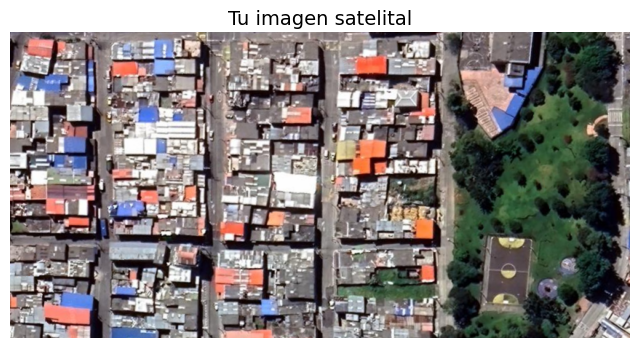

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from PIL import Image
import matplotlib.pyplot as plt

# ========================================
# Ruta a tu imagen satelital en Drive
# Carpeta: Geochat, Archivo: satelite
# ========================================
base_path = '/content/drive/MyDrive/Geochat/satelite'
image_path = None

for ext in ['', '.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp']:
    candidate = base_path + ext
    if os.path.exists(candidate):
        image_path = candidate
        break

if image_path is None:
    folder = '/content/drive/MyDrive/Geochat'
    if os.path.exists(folder):
        print(f' Archivos encontrados en {folder}:')
        for f in os.listdir(folder):
            print(f'   - {f}')
        print('\n Ajusta la variable base_path con el nombre correcto')
    else:
        print(f' La carpeta {folder} no existe en tu Drive')
    raise FileNotFoundError('No se encontró la imagen satelite en Drive/Geochat/')

print(f' Imagen encontrada: {image_path}')

# Cargar y mostrar la imagen
image = Image.open(image_path).convert('RGB')
print(f'   Tamaño: {image.size[0]} x {image.size[1]} píxeles')

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title('Tu imagen satelital', fontsize=14)
plt.axis('off')
plt.show()

In [ ]:
import re
import pathlib

# Ruta al archivo problemático
filepath = pathlib.Path('/content/GeoChat/geochat/model/language_model/mpt/hf_prefixlm_converter.py')

if filepath.exists():
    content = filepath.read_text()

    # Borramos de golpe TODAS las líneas que contengan _expand_mask o _make_causal_mask
    content = re.sub(r'^.*_expand_mask.*$', '', content, flags=re.MULTILINE)
    content = re.sub(r'^.*_make_causal_mask.*$', '', content, flags=re.MULTILINE)

    filepath.write_text(content)
    print(' Archivo hf_prefixlm_converter.py curado definitivamente.')
else:
    print(' No se encontró el archivo. Asegúrate de haber clonado GeoChat correctamente.')

 Archivo hf_prefixlm_converter.py curado definitivamente.


In [ ]:
# ============================================================
# PARCHE 4.5 DEFINITIVO Y LIMPIO: Solución al "DynamicCache"
# ============================================================
import pathlib
import re

arch_path = pathlib.Path('/content/GeoChat/geochat/model/geochat_arch.py')
if arch_path.exists():
    content = arch_path.read_text()

    # 1. Inyectamos una función helper infalible arriba del todo
    helper_func = """
def _get_cache_len(cache):
    if isinstance(cache, tuple): return cache[-1][-1].shape[-2]
    if hasattr(cache, 'get_seq_length'): return cache.get_seq_length()
    if hasattr(cache, 'key_cache'): return cache.key_cache[0].shape[-2]
    if hasattr(cache, 'keys'): return cache.keys[0].shape[-2] if isinstance(cache.keys, list) else cache.keys.shape[-2]
    return 0
"""
    if "_get_cache_len" not in content:
        content = helper_func + "\n" + content

    # 2. Limpiamos cualquier parche anterior fallido y conectamos la función
    content = re.sub(
        r'attention_mask = torch\.ones\(\(attention_mask\.shape\[0\],\s*.*?\s*\+\s*1\)',
        r'attention_mask = torch.ones((attention_mask.shape[0], _get_cache_len(past_key_values) + 1)',
        content
    )

    arch_path.write_text(content)
    print('✅ geochat_arch.py parcheado (Ahora sí, 100% a prueba de versiones).')
    print('🚨 IMPORTANTE: Ve a "Entorno de ejecución" -> "Reiniciar sesión".')
else:
    print('No se encontró el archivo. Asegúrate de estar en /content/GeoChat')

✅ geochat_arch.py parcheado (Ahora sí, 100% a prueba de versiones).
🚨 IMPORTANTE: Ve a "Entorno de ejecución" -> "Reiniciar sesión".


---
## 🤖 Paso 4: Cargar el modelo GeoChat-7B

Descargamos los pesos del modelo desde Hugging Face (~14 GB). Esto toma unos minutos.  
Usamos **cuantización a 4 bits** para que entre en la GPU T4 (16 GB VRAM).

In [ ]:
# 1. Limpiar el historial (pizarrón en blanco)
!cd /content/GeoChat && git checkout geochat/model/multimodal_encoder/clip_encoder.py
!cd /content/GeoChat && git checkout geochat/model/builder.py

import pathlib
import re
import sys
import importlib

# 2. PARCHE 1: builder.py (Evitar el load_in_4bit)
builder_path = pathlib.Path('/content/GeoChat/geochat/model/builder.py')
if builder_path.exists():
    b_content = builder_path.read_text()
    b_content = b_content.replace(
        "**kwargs)",
        "**{k: v for k, v in kwargs.items() if k not in ['load_in_4bit', 'load_in_8bit']})"
    )
    builder_path.write_text(b_content)

# 3. PARCHE 2: clip_encoder.py
clip_path = pathlib.Path('/content/GeoChat/geochat/model/multimodal_encoder/clip_encoder.py')
if clip_path.exists():
    c_content = clip_path.read_text()

    # 3.1: IMITADOR DE SANGRÍA (Tabs vs Spaces resuelto)
    c_content = re.sub(
        r'^([ \t]*)self\.vision_tower = CLIPVisionModel\.from_pretrained\(self\.vision_tower_name\)',
        r'\1if not delay_load:\n\1    self.vision_tower = CLIPVisionModel.from_pretrained(self.vision_tower_name)',
        c_content, flags=re.MULTILINE
    )
    c_content = re.sub(
        r'^([ \t]*)self\.vision_tower\.requires_grad_\(False\)',
        r'\1if not delay_load:\n\1    self.vision_tower.requires_grad_(False)',
        c_content, flags=re.MULTILINE
    )
    c_content = re.sub(
        r'^([ \t]*)self\.clip_interpolate_embeddings\(image_size=504, patch_size=14\)',
        r'\1if not delay_load:\n\1    self.clip_interpolate_embeddings(image_size=504, patch_size=14)',
        c_content, flags=re.MULTILINE
    )

    # 3.2: ERROR "vision_model" (transformers moderno eliminó esta envoltura)
    c_content = c_content.replace(".vision_model.embeddings", ".embeddings")

    # Inyectamos el cargador secundario
    replacement_load = """def load_model(self):
        from transformers import CLIPVisionModel
        self.vision_tower = CLIPVisionModel.from_pretrained(self.vision_tower_name)
        self.vision_tower.requires_grad_(False)
        self.clip_interpolate_embeddings(image_size=504, patch_size=14)
        if hasattr(self, 'dtype'): self.vision_tower.to(self.dtype)
        if hasattr(self, 'device'): self.vision_tower.to(self.device)
        self.is_loaded = True"""
    c_content = re.sub(r'def load_model\(self\):.*?self\.is_loaded = True', replacement_load, c_content, flags=re.DOTALL)
    clip_path.write_text(c_content)
    print(' Parches aplicados con imitación perfecta + Solución AttributeError.')

# Limpiar memoria de Python
for module in list(sys.modules.keys()):
    if 'geochat' in module:
        del sys.modules[module]
importlib.invalidate_caches()

# 4. Entrar a la carpeta y CARGAR
%cd /content/GeoChat
if '/content/GeoChat' not in sys.path:
    sys.path.append('/content/GeoChat')

import torch
from geochat.model.builder import load_pretrained_model
from geochat.mm_utils import get_model_name_from_path

model_path = 'MBZUAI/geochat-7B'
model_name = get_model_name_from_path(model_path)

print(' Cargando modelo GeoChat-7B...')
tokenizer, model, image_processor, context_len = load_pretrained_model(
    model_path,
    None,           # model_base
    model_name,
    load_8bit=False,
    load_4bit=True,
    device='cuda'
)

model = model.eval()
print(f'\n Modelo cargado exitosamente')
print(f'   Modelo: {model_name}')
print(f'   Contexto máximo: {context_len} tokens')
print(f'   VRAM usada: {torch.cuda.memory_allocated() / 1e9:.1f} GB')



Updated 1 path from the index
Updated 1 path from the index
 Parches aplicados con imitación perfecta + Solución AttributeError.
/content/GeoChat
 Cargando modelo GeoChat-7B...
Loading GeoChat......


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/295 [00:00<?, ?it/s]

[transformers] GeoChatLlamaForCausalLM LOAD REPORT from: MBZUAI/geochat-7B
Key                                                                                            | Status     |  | 
-----------------------------------------------------------------------------------------------+------------+--+-
model.vision_tower.vision_tower.vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
model.vision_tower.vision_tower.vision_model.encoder.layers.{0...23}.self_attn.out_proj.weight | UNEXPECTED |  | 
model.vision_tower.vision_tower.vision_model.encoder.layers.{0...23}.mlp.fc2.weight            | UNEXPECTED |  | 
model.vision_tower.vision_tower.vision_model.encoder.layers.{0...23}.self_attn.v_proj.weight   | UNEXPECTED |  | 
model.vision_tower.vision_tower.vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
model.vision_tower.vision_tower.vision_model.encoder.layers.{0...23}.layer_norm2.weight        | UNEXPECTED |  | 
model.vision_

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-large-patch14-336
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_projection.weight                                       | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.ml


 Modelo cargado exitosamente
   Modelo: geochat-7B
   Contexto máximo: 2048 tokens
   VRAM usada: 4.5 GB


In [ ]:
# ============================================================
# PARCHE 3: Arreglar incompatibilidad del caché de memoria (DynamicCache)
# ============================================================
import pathlib

arch_path = pathlib.Path('/content/GeoChat/geochat/model/geochat_arch.py')
if arch_path.exists():
    content = arch_path.read_text()

    # Reemplazamos la forma en la que pide el tamaño de la memoria:
    content = content.replace(
        "past_key_values[-1][-1].shape[-2]",
        "(past_key_values.get_seq_length() if hasattr(past_key_values, 'get_seq_length') else past_key_values[-1][-1].shape[-2])"
    )

    arch_path.write_text(content)
    print(' geochat_arch.py parcheado (DynamicCache error solucionado).')
    print(' AHORA HAZ ESTO: Ve al menú "Entorno de ejecución" -> "Reiniciar sesión".')
else:
    print('No se encontró el archivo. Asegúrate de haber clonado el repo primero.')

 geochat_arch.py parcheado (DynamicCache error solucionado).
 AHORA HAZ ESTO: Ve al menú "Entorno de ejecución" -> "Reiniciar sesión".


---
## 💬 Paso 5: Función para hacer preguntas sobre la imagen

Creamos una función auxiliar que:
1. Preprocesa la imagen con el procesador de CLIP
2. Formatea el prompt en el formato que espera el modelo (LLaVA-style)
3. Genera la respuesta

In [ ]:
import torch
from geochat.conversation import conv_templates, SeparatorStyle
from geochat.constants import IMAGE_TOKEN_INDEX, DEFAULT_IMAGE_TOKEN
from geochat.mm_utils import tokenizer_image_token, KeywordsStoppingCriteria

def preguntar_geochat(imagen_pil, pregunta, max_tokens=512):
    # Preprocesar imagen forzando la resolución HD de 504x504 que exige GeoChat
    image_tensor = image_processor.preprocess(
        imagen_pil,
        return_tensors='pt',
        size={"shortest_edge": 504},
        crop_size={"height": 504, "width": 504}
    )['pixel_values'].half().cuda()

    # Preparar el texto
    qs = pregunta
    if DEFAULT_IMAGE_TOKEN not in qs:
        qs = DEFAULT_IMAGE_TOKEN + '\n' + qs

    # Usar la plantilla original
    conv = conv_templates["llava_v1"].copy()
    conv.append_message(conv.roles[0], qs)
    conv.append_message(conv.roles[1], None)
    prompt = conv.get_prompt()

    # Tokenizar
    input_ids = tokenizer_image_token(prompt, tokenizer, IMAGE_TOKEN_INDEX, return_tensors='pt').unsqueeze(0).cuda()

    # Criterio de parada
    stop_str = conv.sep if conv.sep_style != SeparatorStyle.TWO else conv.sep2
    stopping_criteria = KeywordsStoppingCriteria([stop_str], tokenizer, input_ids)

    # Generar respuesta sin caché para evitar bucles
    with torch.inference_mode():
        output_ids = model.generate(
            input_ids,
            images=image_tensor,
            max_new_tokens=max_tokens,
            do_sample=True,
            temperature=0.2,
            top_p=0.9,
            use_cache=False,
            stopping_criteria=[stopping_criteria]
        )

    outputs = tokenizer.batch_decode(output_ids[:, input_ids.shape[1]:], skip_special_tokens=True)[0]
    return outputs.strip()

print("✅ Función lista. Resolución visual forzada a 504x504 HD.")

✅ Función lista. Resolución visual forzada a 504x504 HD.


---
## 🚀 Paso 6: ¡Probemos GeoChat con tu imagen satelital!

Vamos a hacer varias preguntas para demostrar las capacidades del modelo.

In [ ]:
print('='*60)
print('📝 EJEMPLO: Descripción de la imagen satelital')
print('='*60)

pregunta = 'Describe this satellite image in detail. Please output your response completely in Spanish.'
respuesta = preguntar_geochat(image, pregunta)

print(f'\n🤖 GeoChat dice:\n{respuesta}')

[transformers] Both `max_new_tokens` (=512) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


📝 EJEMPLO: Descripción de la imagen satelital

🤖 GeoChat dice:
En la imagen satelital, se pueden observar varios edificios y una calle en un entorno urbanizado. Los edificios se encuentran en diferentes partes de la imagen, con algunos en el centro y otros en los lados. La calle se encuentra en la parte inferior de la imagen, con algunos edificios cercanos a ella. En general, la imagen presenta una vista panorámica de un área urbana con varios edificios y una calle principal.


---
## 📊 Resumen: ¿Cómo funciona internamente?

```
┌─────────────────────────────────────────────────────────┐
│                    FLUJO DE GeoChat                     │
├─────────────────────────────────────────────────────────┤
│                                                         │
│  1. Tu imagen satelital (ej: 1024x1024 px)              │
│         │                                               │
│         ▼                                               │
│  2. CLIP ViT-L/14 (encoder visual)                      │
│     - Redimensiona a 336x336                            │
│     - Extrae 576 tokens visuales                        │
│         │                                               │
│         ▼                                               │
│  3. Proyector MLP (2 capas + GELU)                      │
│     - Traduce features visuales → espacio de texto      │
│         │                                               │
│         ▼                                               │
│  4. Vicuna-7B (LLM)                                     │
│     - Recibe: [tokens visuales] + [tu pregunta]         │
│     - Genera: respuesta en lenguaje natural             │
│         │                                               │
│         ▼                                               │
│  5. Respuesta: "The image shows an urban area with..."  │
│                                                         │
└─────────────────────────────────────────────────────────┘
```

### Diferencia clave con modelos genéricos

GeoChat fue **entrenado específicamente con 318K ejemplos de teledetección**, lo que le da conocimiento especializado sobre:
- Tipos de uso de suelo
- Infraestructura vista desde arriba
- Vegetación y cuerpos de agua
- Patrones urbanos/rurales

Esto lo hace mucho más preciso que un modelo de visión genérico para analizar imágenes satelitales. 🛰️